# 04 Payoff and ADUs by 2031

Where does an ADU pay off, and how many could be built by 2031?

**Inputs**
- `data/processed/acs_tract.csv`
- `data/processed/mortgage_rate_year.csv`
- `data/processed/decennial_units_tract.csv` (crosswalked in notebook 01, read from `tract_panel.csv`)
- `data/processed/access_tract.csv` (notebook 03)
- `data/processed/lots_tract.csv (from MUSA 6950)`. If it is not there yet, a fallback is used. Rerun this notebook once it exists
- `shared/legal_status.csv`
- `data/raw/5500/jobs/pa_xwalk.csv.gz` and `pa_rac_2024.csv.gz` (to split tracts into towns)

**Output (the tool reads this)**
- `data/processed/payoff_tract.csv  (GEOID, rent_est, cost_month, pays) and data/processed/forecast_town.csv  (town_geoid, rule, adus_low, adus_mid, adus_high)`

Run `python musa5500/get_data.py` first.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parents[1] if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "shared"))
from common import RAW, OUT, ACS_YEARS

FIG = ROOT / "musa5500" / "docs" / "figures"

## Assumptions

- Keep every number here so it is easy to change and report

In [2]:
SIZE_SQFT = 600
COST_PER_SQFT = {"low": 175, "mid": 250, "high": 300}
SOFT_COST = 0.15
LOAN_YEARS = 30
OPEX_SHARE = 0.30   # vacancy, repairs, tax, insurance
rates = pd.read_csv(OUT / "mortgage_rate_year.csv")
rate = rates.pmms30.iloc[-1] / 100
RATE_YEAR = int(rates.year.iloc[-1])

# Rent for the ADU = tract median gross rent (ACS 2020-24, 2024 dollars) x this factor.
# 1.0 in the main run. ADUs are small (lower rent) but new (higher rent). 0.9 and 1.1 are tested below.
RENT_FACTOR = 1.0

# Forecast settings
YEARS = 5                                  # 2027 to 2031
PEW_PER_100K = {"low": 26, "mid": 53.5, "high": 81}   # ADU permits per 100,000 people per year in permissive cities (Pew)
PAYS_WEIGHT = {"yes": 1.0, "maybe": 0.5, "no": 0.2}   # share of the Pew rate. "no" is not 0: some people build for family, not rent
RULE_FACTOR = {                            # share of the full rate under each rule today
    "allowed": {"low": 1.0, "mid": 1.0, "high": 1.0},
    "limited": {"low": 0.02, "mid": 0.05, "high": 0.10},
    "not_allowed": {"low": 0.0, "mid": 0.0, "high": 0.0},
}
UNLISTED_RULE = "limited"                  # towns not in legal_status.csv
print(f"Latest PMMS 30-year rate: {rate:.2%} ({RATE_YEAR} average)")

Latest PMMS 30-year rate: 6.53% (2026 average)


## Payoff test

- Monthly payment = numpy_financial.pmt or the formula P*r/(1-(1+r)^-n)
- pays = yes / close (within 10%) / no
- What the code does:
  - cost_month = payment on the mid build cost ($250 / sq ft + 15% soft costs), all borrowed, 30 years at the latest PMMS rate
  - net rent = rent_est x (1 - 30%)
  - yes = net rent covers cost_month
  - maybe = net rent covers the payment at the low build cost ($175 / sq ft), or is within 10% of cost_month
  - no = everything else
  - no rent in the ACS = blank

In [3]:
def payment(principal, r=rate, years=LOAN_YEARS):
    m = r / 12
    n = years * 12
    return principal * m / (1 - (1 + m) ** -n)


build = {k: SIZE_SQFT * v * (1 + SOFT_COST) for k, v in COST_PER_SQFT.items()}
pay = {k: payment(v) for k, v in build.items()}
print(pd.DataFrame({"build cost": build, "monthly payment": pay}).round(0))
print("Gross rent needed to break even (mid cost):", round(pay["mid"] / (1 - OPEX_SHARE)))
print("Gross rent needed to break even (low cost):", round(pay["low"] / (1 - OPEX_SHARE)))

panel = pd.read_csv(OUT / "tract_panel.csv", dtype={"GEOID": str, "county": str})


def pays_test(rent, cost_mid, cost_low):
    net = rent * (1 - OPEX_SHARE)
    out = np.where(net >= cost_mid, "yes", np.where((net >= cost_low) | (net >= 0.9 * cost_mid), "maybe", "no"))
    return pd.Series(out, index=rent.index).where(rent.notna())


payoff = panel[["GEOID"]].copy()
payoff["rent_est"] = (panel.median_rent_2024 * RENT_FACTOR).round(0)
payoff["net_rent"] = (payoff.rent_est * (1 - OPEX_SHARE)).round(0)
payoff["cost_month"] = round(pay["mid"])
payoff["cost_month_low"] = round(pay["low"])
payoff["pays"] = pays_test(payoff.rent_est, pay["mid"], pay["low"])
payoff["margin"] = payoff.net_rent - payoff.cost_month
print(payoff.pays.value_counts(dropna=False))
print("Share of tracts with rent data:", payoff.pays.value_counts(normalize=True).round(3).to_dict())

      build cost  monthly payment
low     120750.0            766.0
mid     172500.0           1094.0
high    207000.0           1312.0
Gross rent needed to break even (mid cost): 1562
Gross rent needed to break even (low cost): 1094
pays
no       1439
maybe    1159
yes       663
NaN       184
Name: count, dtype: int64
Share of tracts with rent data: {'no': 0.441, 'maybe': 0.355, 'yes': 0.203}


### Share of people who live in each payoff class

- Weighted by 2020-24 population

In [4]:
w = payoff.merge(panel[["GEOID", "pop_2024", "county"]], on="GEOID")
(w.groupby(w.pays.fillna("no rent data")).pop_2024.sum() / w.pop_2024.sum()).round(3)

pays
maybe           0.362
no              0.377
no rent data    0.040
yes             0.221
Name: pop_2024, dtype: float64

### Sensitivity

- Share of tracts (with rent data) in each class, for each rent factor and build cost
- For build cost "x", yes = covers cost x, maybe = covers the low-cost payment or is within 10%

In [5]:
rows = []
for rf in [0.9, 1.0, 1.1]:
    for k in ["low", "mid", "high"]:
        p = pays_test(panel.median_rent_2024 * rf, pay[k], pay["low"]).dropna()
        rows.append({"rent factor": rf, "build cost": k, "yes": (p == "yes").mean(),
                     "maybe": (p == "maybe").mean(), "no": (p == "no").mean()})
sens = pd.DataFrame(rows)
sens.round(3)

,rent factor,build cost,yes,maybe,no
0,0.9,low,0.438,0.121,0.441
1,0.9,mid,0.131,0.307,0.562
2,0.9,high,0.054,0.385,0.562
3,1.0,low,0.559,0.108,0.334
4,1.0,mid,0.203,0.355,0.441
5,1.0,high,0.092,0.467,0.441
6,1.1,low,0.652,0.115,0.233
7,1.1,mid,0.277,0.375,0.348
8,1.1,high,0.144,0.508,0.348


### Which counties pay off

- Counties with the most tracts where an ADU pays (yes)

In [6]:
cnames = gpd.read_file(OUT / "counties_2020.gpkg")[["GEOID", "NAME"]].rename(columns={"GEOID": "county"})
w = w.merge(payoff[["GEOID", "rent_est"]].rename(columns={"rent_est": "rent"}), on="GEOID")
byc = w.dropna(subset=["pays"]).groupby("county").agg(tracts=("GEOID", "size"), yes=("pays", lambda s: (s == "yes").sum()),
                                                      maybe=("pays", lambda s: (s == "maybe").sum()),
                                                      median_rent=("rent", "median"))
byc = byc.merge(cnames, left_index=True, right_on="county").set_index("NAME").drop(columns="county")
byc["share_yes_or_maybe"] = ((byc.yes + byc.maybe) / byc.tracts).round(3)
byc.sort_values(["yes", "share_yes_or_maybe"], ascending=False).head(10)

,tracts,yes,maybe,median_rent,share_yes_or_maybe
NAME,,,,,
Philadelphia,383,124,194,1372.0,0.830
Montgomery,204,121,74,1682.5,0.956
Chester,112,70,33,1708.5,0.920
Bucks,126,69,49,1669.5,0.937
Delaware,140,48,78,1376.0,0.900
Allegheny,366,47,167,1141.5,0.585
Lehigh,80,26,45,1384.5,0.888
Northampton,71,25,37,1419.0,0.873
Lancaster,115,24,77,1317.0,0.878


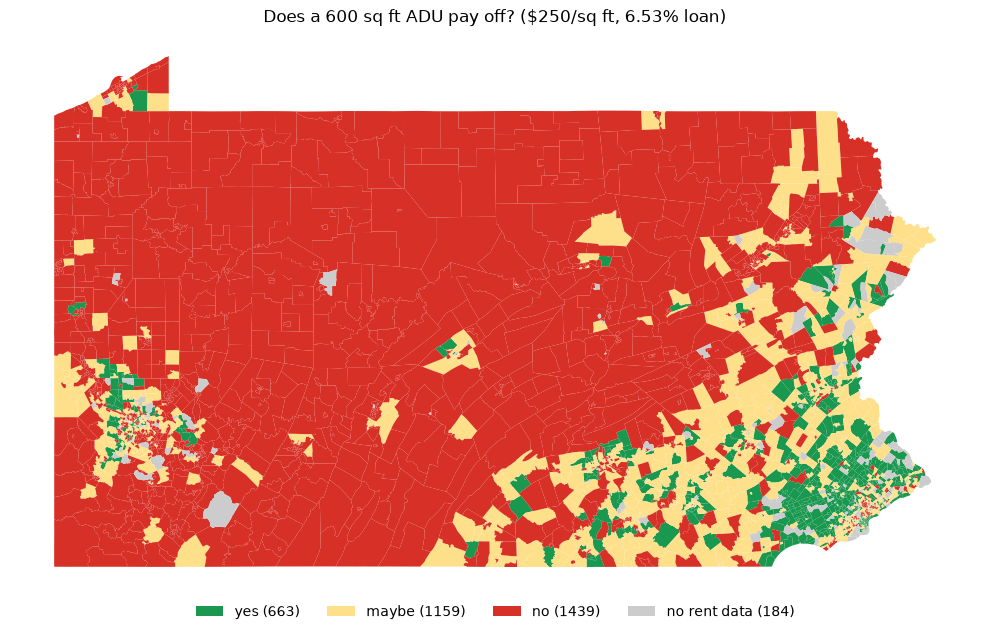

In [7]:
tracts = gpd.read_file(OUT / "tracts_2020.gpkg")
g = tracts.merge(payoff, on="GEOID").to_crs(3857)
colors = {"yes": "#1a9850", "maybe": "#fee08b", "no": "#d73027"}
fig, ax = plt.subplots(figsize=(10, 6.5))
for k, c in colors.items():
    sub = g[g.pays == k]
    sub.plot(ax=ax, color=c, linewidth=0, label=f"{k} ({len(sub)})")
g[g.pays.isna()].plot(ax=ax, color="#cccccc", linewidth=0, label=f"no rent data ({g.pays.isna().sum()})")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, 0), ncol=4, frameon=False)
ax.set_axis_off()
ax.set_title(f"Does a 600 sq ft ADU pay off? (${COST_PER_SQFT['mid']}/sq ft, {rate:.2%} loan)")
fig.tight_layout()
fig.savefig(FIG / "04_payoff_map.png", dpi=150)

## Random forest: housing growth 2010 -> 2020

- Target: units_2020 / units_2010 by tract (decennial, crosswalked)
- Predictors from 2010 or earlier only
- cross_val_score, R2, feature_importances_
- What the code does:
  - Target = log(units 2020 / units 2010). Log keeps a few fast-growing tracts from taking over. Tracts with under 100 homes in 2010 are left out
  - Model A uses only 2010 data: decennial homes 2010, LODES jobs and workers 2010, NLCD 2010, land area, location
  - Model B adds ACS 2010-14 (renter share, single-family share, vacancy, rent, value, income). There is no ACS 2006-10 in our data. 2010-14 overlaps the target period a little, so model B is a small leak. It is shown for comparison
  - Two checks: random 5-fold CV, and spatial CV (5 folds that hold out whole counties). The spatial one is the honest number for new places

In [8]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import cross_val_score, cross_val_predict, KFold, GroupKFold
from sklearn.metrics import r2_score, mean_absolute_error

access = pd.read_csv(OUT / "access_tract.csv", dtype={"GEOID": str})
tg = tracts.to_crs(5070)
geo = pd.DataFrame({"GEOID": tg.GEOID, "area_km2": tg.area / 1e6, "x": tg.centroid.x / 1000, "y": tg.centroid.y / 1000})
df = panel.merge(access[["GEOID", "dev_2010", "devhi_2010", "dev_2019", "devhi_2019"]], on="GEOID", how="left").merge(geo, on="GEOID")


def features(d, base):
    """Build predictors for a base year. base=2010 for training, base=2020 for the forecast."""
    yr = {2010: {"units": "dec_units_2010", "jobs": 2010, "dev": 2010, "acs": 2014},
          2020: {"units": "dec_units_2020", "jobs": 2019, "dev": 2019, "acs": 2024}}[base]
    f = pd.DataFrame(index=d.index)
    units = d[yr["units"]]
    f["log_units"] = np.log1p(units)
    f["units_per_km2"] = units / d.area_km2
    f["log_jobs"] = np.log1p(d[f"jobs_here_{yr['jobs']}"])
    f["log_workers"] = np.log1p(d[f"workers_living_here_{yr['jobs']}"])
    f["jobs_per_unit"] = d[f"jobs_here_{yr['jobs']}"] / units.clip(lower=1)
    f["dev_share"] = d[f"dev_{yr['dev']}"]
    f["devhi_share"] = d[f"devhi_{yr['dev']}"]
    f["log_area"] = np.log(d.area_km2)
    f["x"], f["y"] = d.x, d.y
    a = yr["acs"]
    acsf = pd.DataFrame(index=d.index)
    hu = d[f"housing_units_{a}"].clip(lower=1)
    acsf["renter_share"] = d[f"renter_units_{a}"] / d[f"occupied_units_{a}"].clip(lower=1)
    acsf["sfd_share"] = d[f"single_family_detached_{a}"] / hu
    acsf["vacancy"] = d[f"vacant_units_{a}"] / hu
    acsf["median_rent"] = d[f"median_rent_{a}"]
    acsf["median_value"] = d[f"median_value_{a}"]
    acsf["median_income"] = d[f"median_income_{a}"]
    return f, acsf


fa, fb = features(df, 2010)
train = (df.dec_units_2010 >= 100) & (df.dec_units_2020 > 0)
y = np.log(df.dec_units_2020 / df.dec_units_2010)[train]
XA = fa[train].replace([np.inf, -np.inf], np.nan)
XA = XA.fillna(XA.median())
XB = pd.concat([fa, fb], axis=1)[train].replace([np.inf, -np.inf], np.nan)
# Random forest cannot take blanks. Fill the few blank medians with the county median, then the state median
XB = XB.groupby(df.county[train]).transform(lambda s: s.fillna(s.median())).fillna(XB.median())
groups = df.county[train]
print(len(y), "training tracts. Target median growth 2010-20:", f"{np.expm1(y.median()):.2%}")

rf = RandomForestRegressor(n_estimators=400, min_samples_leaf=5, n_jobs=-1, random_state=0)
res = []
cvp = {}
for name, X in [("A: 2010 only", XA), ("B: + ACS 2010-14", XB)]:
    r_rand = cross_val_score(rf, X, y, cv=KFold(5, shuffle=True, random_state=0), scoring="r2")
    r_sp = cross_val_score(rf, X, y, cv=GroupKFold(5), groups=groups, scoring="r2")
    p = cross_val_predict(rf, X, y, cv=GroupKFold(5), groups=groups)
    cvp[name] = p
    res.append({"model": name, "R2 random CV": r_rand.mean(), "R2 spatial CV": r_sp.mean(),
                "R2 spatial (pooled)": r2_score(y, p), "MAE spatial (log pts)": mean_absolute_error(y, p)})
cv = pd.DataFrame(res).set_index("model")
cv.round(3)

/opt/anaconda3/envs/geospatial/lib/python3.14/site-packages/pandas/core/arraylike.py:402: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)


3394 training tracts. Target median growth 2010-20: 1.31%


,R2 random CV,R2 spatial CV,R2 spatial (pooled),MAE spatial (log pts)
model,,,,
A: 2010 only,0.279,0.202,0.216,0.100
B: + ACS 2010-14,0.296,0.213,0.230,0.097


### Is the model better than a simple rule?

- Baseline: give every tract the statewide median growth. Its R2 is about 0
- So any R2 above 0 in spatial CV is real skill

In [9]:
base = r2_score(y, np.full(len(y), y.median()))
print("Baseline R2 (state median for every tract):", round(base, 3))

Baseline R2 (state median for every tract): -0.002


Model used for the forecast: A: 2010 only


log_workers      0.484
log_units        0.226
jobs_per_unit    0.047
dev_share        0.044
units_per_km2    0.041
x                0.039
log_area         0.036
devhi_share      0.031
y                0.030
log_jobs         0.022
dtype: float64

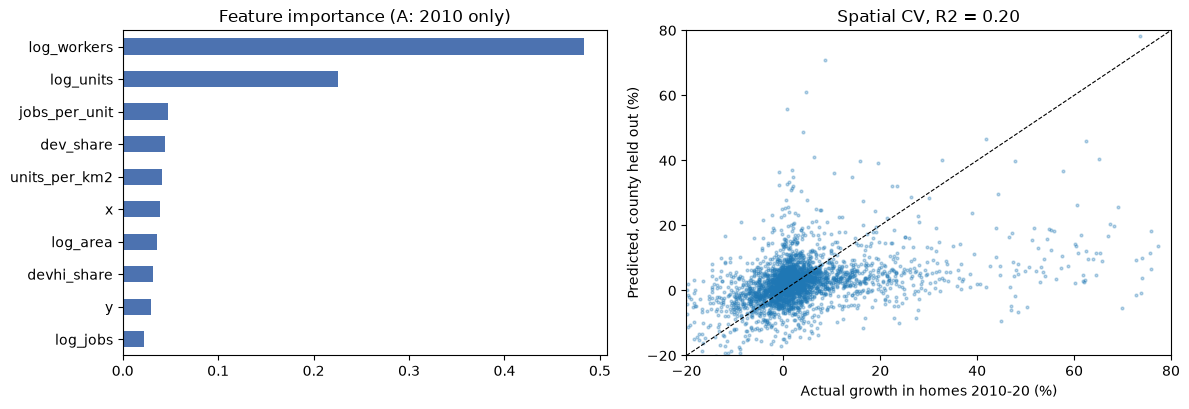

In [10]:
# Use model A (no leak) unless B is clearly better in spatial CV (more than 0.02 R2)
A_, B_ = cv.index
best = B_ if cv.loc[B_, "R2 spatial CV"] - cv.loc[A_, "R2 spatial CV"] > 0.02 else A_
Xbest = XA if best.startswith("A") else XB
rf.fit(Xbest, y)
imp = pd.Series(rf.feature_importances_, index=Xbest.columns).sort_values()
print("Model used for the forecast:", best)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
imp.plot.barh(ax=axes[0], color="#4c72b0")
axes[0].set_title(f"Feature importance ({best})")
p = cvp[best]
axes[1].scatter(np.expm1(y) * 100, np.expm1(p) * 100, s=4, alpha=0.3)
lim = [-20, 80]
axes[1].plot(lim, lim, "k--", lw=0.8)
axes[1].set_xlim(lim); axes[1].set_ylim(lim)
axes[1].set_xlabel("Actual growth in homes 2010-20 (%)")
axes[1].set_ylabel("Predicted, county held out (%)")
axes[1].set_title(f"Spatial CV, R2 = {cv.loc[best, 'R2 spatial CV']:.2f}")
fig.tight_layout()
fig.savefig(FIG / "04_rf.png", dpi=150)
imp.sort_values(ascending=False).round(3)

### Forecast of housing growth from 2020

- Same model, fed 2020 values (decennial 2020 homes, LODES 2019, NLCD 2019, ACS 2020-24 for model B)
- Gives a predicted 10-year growth per tract. Used only as a ranking of demand in the ADU forecast

In [11]:
fa20, fb20 = features(df, 2020)
X20 = fa20 if best.startswith("A") else pd.concat([fa20, fb20], axis=1)
X20 = X20.groupby(df.county).transform(lambda s: s.fillna(s.median())).fillna(Xbest.median())
X20 = X20.replace([np.inf, -np.inf], np.nan).fillna(Xbest.median())
df["pred_growth"] = np.expm1(rf.predict(X20[Xbest.columns]))
df["demand_factor"] = 0.5 + df.pred_growth.rank(pct=True)   # 0.5 (slowest) to 1.5 (fastest)
df.pred_growth.describe().round(4)

count    3445.0000
mean        0.0249
std         0.1698
min        -0.9041
25%        -0.0021
50%         0.0276
75%         0.0525
max         3.2709
Name: pred_growth, dtype: float64

## ADUs by 2031

- lots with room x allowed x uptake x 5 years
- Two rules: current and hb2186
- Low / mid / high
- Check: 26-81 per 100,000 people per year (Pew)

How the code does it:
- Start from the Pew rate: 26 (low), 53.5 (mid), 81 (high) ADU permits per 100,000 people per year. These rates come from cities that allow ADUs by right
- Scale it for each tract by three factors:
  - payoff: yes 1.0, maybe 0.5, no 0.2 (no rent data = 0.2)
  - lots: share of homes on a lot with room, divided by the state average, capped at 2. From MUSA 6950 if `lots_tract.csv` exists, else single-family detached share (ACS 2020-24) as the fallback
  - demand: 0.5 to 1.5 from the random forest ranking
- Split each tract into towns by where workers live (LODES 2024 RAC by block), then apply the town rule
- Rule today: allowed 1.0. Limited 0.02 / 0.05 / 0.10. Not allowed 0. Towns not in `legal_status.csv` are treated as limited
- HB 2186: every town counts as allowed
- 5 years (2027-2031). Capped at the number of lots with room (fallback: single-family detached homes)

In [12]:
lots_file = OUT / "lots_tract.csv"
USE_LOTS = lots_file.exists()
df["hu"] = df.housing_units_2024.clip(lower=1)
df["sfd_share"] = df.single_family_detached_2024 / df.hu
df["lots_cap"] = df.single_family_detached_2024
df["lots_source"] = "fallback: single-family detached share"
ref = df.single_family_detached_2024.sum() / df.housing_units_2024.sum()
df["lots_index"] = (df.sfd_share / ref).clip(upper=2)
if USE_LOTS:
    lots = pd.read_csv(lots_file, dtype={"GEOID": str})
    df = df.merge(lots[["GEOID", "lots_total", "lots_fit"]], on="GEOID", how="left")
    has = df.lots_fit.notna()
    ref6950 = df.loc[has, "lots_fit"].sum() / df.loc[has, "hu"].sum()
    df.loc[has, "lots_index"] = (df.loc[has, "lots_fit"] / df.loc[has, "hu"] / ref6950).clip(upper=2)
    df.loc[has, "lots_cap"] = df.loc[has, "lots_fit"]
    df.loc[has, "lots_source"] = "MUSA 6950 lots_tract.csv"
print("Using lots_tract.csv:", USE_LOTS)
print(df.lots_source.value_counts())
print("Statewide single-family detached share (fallback reference):", round(ref, 3))

df = df.merge(payoff[["GEOID", "pays"]], on="GEOID", how="left")
df["pays_weight"] = df.pays.map(PAYS_WEIGHT).fillna(PAYS_WEIGHT["no"])
df["factor"] = df.pays_weight * df.lots_index * df.demand_factor
df[["pays_weight", "lots_index", "demand_factor", "factor"]].describe().round(3)

Using lots_tract.csv: True
lots_source
MUSA 6950 lots_tract.csv    3445
Name: count, dtype: int64
Statewide single-family detached share (fallback reference): 0.566


,pays_weight,lots_index,demand_factor,factor
count,3445.000,3445.000,3445.000,3445.000
mean,0.455,1.001,1.000,0.441
std,0.297,0.562,0.289,0.468
min,0.200,0.000,0.500,0.000
25%,0.200,0.566,0.750,0.149
50%,0.500,1.080,1.000,0.252
75%,0.500,1.424,1.250,0.582
max,1.000,2.000,1.500,2.965


### Split tracts into towns

- Block to town and tract comes from the LODES crosswalk
- Weight = workers living in the block (LODES RAC 2024). Blocks with no workers get a tiny weight so every tract has a town
- Three crosswalk town codes do not match the 2020 town map (Mount Lebanon, Penn Hills renamed codes, and one blank). Those blocks are placed by a spatial join

In [13]:
xw = pd.read_csv(RAW / "5500" / "jobs" / "pa_xwalk.csv.gz", dtype=str,
                 usecols=["tabblk2020", "trct", "ctycsub", "blklatdd", "blklondd"])
rac = pd.read_csv(RAW / "5500" / "jobs" / "pa_rac_2024.csv.gz", dtype={"h_geocode": str}, usecols=["h_geocode", "C000"])
xw = xw.merge(rac, left_on="tabblk2020", right_on="h_geocode", how="left")
xw["wt"] = xw.C000.fillna(0) + 0.01
towns = gpd.read_file(OUT / "towns_2020.gpkg")
bad = ~xw.ctycsub.isin(towns.GEOID)
pts = gpd.GeoDataFrame(xw[bad], geometry=gpd.points_from_xy(xw[bad].blklondd.astype(float), xw[bad].blklatdd.astype(float)), crs=4326)
fix = gpd.sjoin_nearest(pts.to_crs(5070), towns[["GEOID", "geometry"]].to_crs(5070))[["GEOID"]]
xw.loc[fix.index, "ctycsub"] = fix.GEOID.values
print("blocks fixed:", int(bad.sum()), " towns covered:", xw.ctycsub.nunique(), "of", len(towns))
split = xw.groupby(["trct", "ctycsub"]).wt.sum().reset_index()
split["share"] = split.wt / split.groupby("trct").wt.transform("sum")
split = split.rename(columns={"trct": "GEOID", "ctycsub": "town_geoid"})

blocks fixed: 903  towns covered: 2571 of 2572


In [14]:
legal = pd.read_csv(ROOT / "shared" / "legal_status.csv", dtype={"GEOID": str}, comment="#")
rule_today = towns[["GEOID", "NAMELSAD"]].merge(legal[["GEOID", "adu_rule"]], on="GEOID", how="left")
rule_today["listed"] = rule_today.adu_rule.notna()
rule_today["adu_rule"] = rule_today.adu_rule.replace("unknown", np.nan).fillna(UNLISTED_RULE)
rule_today = rule_today.rename(columns={"GEOID": "town_geoid", "NAMELSAD": "name"})
print(legal.adu_rule.value_counts())

pieces = split.merge(df[["GEOID", "pop_2024", "factor", "lots_cap"]], on="GEOID").merge(rule_today, on="town_geoid")
pieces["pop"] = pieces.pop_2024 * pieces.share
pieces["cap"] = pieces.lots_cap.fillna(0) * pieces.share

out = []
for rule in ["current", "hb2186"]:
    r = pieces.copy()
    r["rule"] = rule
    for lvl in ["low", "mid", "high"]:
        rf_ = 1.0 if rule == "hb2186" else r.adu_rule.map(lambda a: RULE_FACTOR[a][lvl])
        est = r["pop"] / 1e5 * PEW_PER_100K[lvl] * r.factor * rf_ * YEARS
        r[f"adus_{lvl}"] = np.minimum(est, r.cap)
    out.append(r)
pieces_out = pd.concat(out)
forecast = (pieces_out.groupby(["town_geoid", "name", "adu_rule", "listed", "rule"])
            .agg(pop=("pop", "sum"), adus_low=("adus_low", "sum"), adus_mid=("adus_mid", "sum"), adus_high=("adus_high", "sum"))
            .reset_index().rename(columns={"adu_rule": "rule_today"}))
for c in ["pop", "adus_low", "adus_mid", "adus_high"]:
    forecast[c] = forecast[c].round(1)
print(forecast.groupby("rule").size())

adu_rule
limited    7
allowed    2
Name: count, dtype: int64
rule
current    2571
hb2186     2571
dtype: int64


### Totals and the Pew check

- Statewide ADUs by 2031 and per year
- Pew range for all of PA if every town acted like a permissive city: 26 to 81 per 100,000 people per year

In [15]:
pop_pa = df.pop_2024.sum()
tot = forecast.groupby("rule")[["adus_low", "adus_mid", "adus_high"]].sum()
per_year = tot / YEARS
per_100k = per_year / pop_pa * 1e5
summary = pd.concat({"by 2031": tot, "per year": per_year, "per 100k per year": per_100k}, axis=1).round(1)
print(f"PA population (ACS 2020-24): {pop_pa:,.0f}")
print(f"Pew range for PA per year: {pop_pa / 1e5 * 26:,.0f} to {pop_pa / 1e5 * 81:,.0f}")
summary.T

PA population (ACS 2020-24): 13,018,639
Pew range for PA per year: 3,385 to 10,545


rule                         current   hb2186
by 2031           adus_low     196.5   8194.5
                  adus_mid     927.9  16861.1
                  adus_high   2692.7  25525.7
per year          adus_low      39.3   1638.9
                  adus_mid     185.6   3372.2
                  adus_high    538.5   5105.1
per 100k per year adus_low       0.3     12.6
                  adus_mid       1.4     25.9
                  adus_high      4.1     39.2

In [16]:
permits = pd.read_csv(OUT / "permits_county.csv")
recent = permits[permits.year >= permits.year.max() - 4].groupby("year").units_total.sum()
print("New homes permitted in PA per year (Census BPS):")
print(recent)
print("HB 2186 mid ADUs per year as a share of recent average permits:",
      round(per_year.loc["hb2186", "adus_mid"] / recent.mean(), 3))

New homes permitted in PA per year (Census BPS):
year
2021    47894
2022    28149
2023    25320
2024    24810
2025    25709
Name: units_total, dtype: int64
HB 2186 mid ADUs per year as a share of recent average permits: 0.111


In [17]:
top = forecast[forecast.rule == "hb2186"].nlargest(10, "adus_mid")[["town_geoid", "name", "rule_today", "pop", "adus_low", "adus_mid", "adus_high"]]
cur = forecast[forecast.rule == "current"].set_index("town_geoid").adus_mid
top["current_mid"] = top.town_geoid.map(cur)
top.round(0)

,town_geoid,name,rule_today,pop,adus_low,adus_mid,adus_high,current_mid
3943,4210160000,Philadelphia city,limited,1579706.0,195.0,401.0,606.0,20.0
245,4200361000,Pittsburgh city,limited,304759.0,114.0,234.0,353.0,12.0
3631,4209144976,Lower Merion township,limited,64174.0,67.0,137.0,208.0,7.0
2107,4204533144,Haverford township,limited,50874.0,61.0,126.0,191.0,6.0
3589,4209100156,Abington township,limited,58664.0,59.0,121.0,183.0,6.0
2019,4204345056,Lower Paxton township,limited,54657.0,58.0,118.0,179.0,6.0
961,4201754688,Northampton township,limited,39920.0,55.0,113.0,172.0,6.0
909,4201708768,Bristol township,limited,54173.0,55.0,113.0,171.0,6.0
943,4201749120,Middletown township,limited,45793.0,51.0,104.0,158.0,5.0
2913,4207146896,Manheim township,limited,44436.0,48.0,100.0,151.0,5.0


In [18]:
listed = forecast[forecast.listed].pivot_table(index=["name", "rule_today"], columns="rule", values="adus_mid").round(1)
listed

,rule,current,hb2186
name,rule_today,,
Allentown city,allowed,76.1,76.1
Doylestown borough,limited,0.8,15.2
East Brandywine township,limited,0.4,7.9
Harrisburg city,limited,0.6,11.2
Malvern borough,limited,0.3,6.6
Philadelphia city,limited,20.0,400.6
Pittsburgh city,limited,11.7,234.1
West Vincent township,allowed,29.3,29.3
Westtown township,limited,2.0,39.8


### Philadelphia check

- Philadelphia has allowed ADUs in parts of the city since 2012. About 10 were built legally (proposal)
- So the current-rule number for Philadelphia should be small

In [19]:
forecast[forecast.town_geoid == "4210160000"][["rule", "pop", "adus_low", "adus_mid", "adus_high"]]

,rule,pop,adus_low,adus_mid,adus_high
3942,current,1579706.0,3.9,20.0,60.6
3943,hb2186,1579706.0,194.7,400.6,606.5


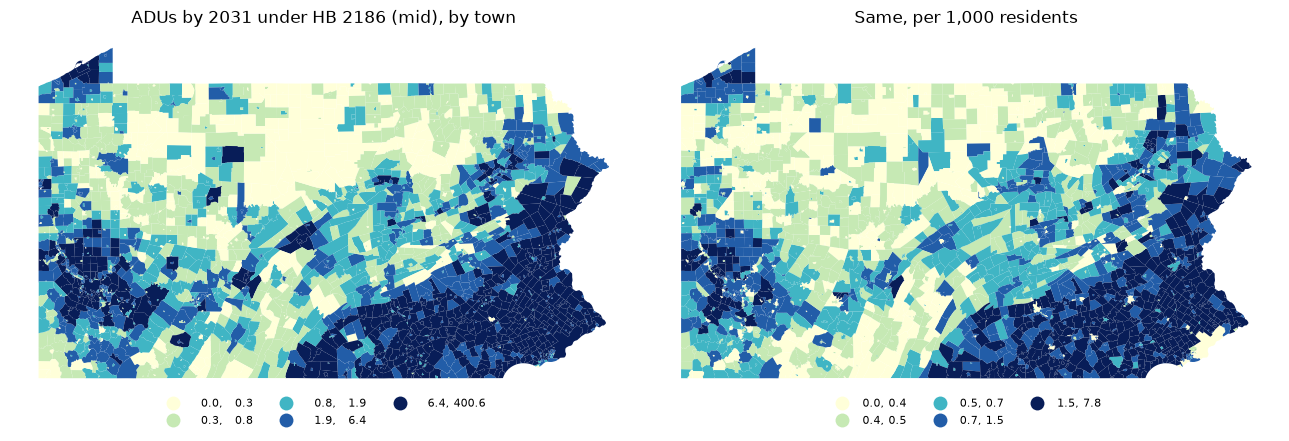

In [20]:
tw = towns.merge(forecast[forecast.rule == "hb2186"][["town_geoid", "pop", "adus_mid"]], left_on="GEOID", right_on="town_geoid").to_crs(3857)
tw["per_1000"] = tw.adus_mid / tw["pop"].clip(lower=1) * 1000
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))
tw.plot(column="adus_mid", ax=axes[0], cmap="YlGnBu", scheme="quantiles", k=5, legend=True,
        legend_kwds={"loc": "upper center", "bbox_to_anchor": (0.5, 0.02), "ncol": 3, "fontsize": 8, "frameon": False, "fmt": "{:.1f}"})
axes[0].set_title("ADUs by 2031 under HB 2186 (mid), by town")
tw.plot(column="per_1000", ax=axes[1], cmap="YlGnBu", scheme="quantiles", k=5, legend=True,
        legend_kwds={"loc": "upper center", "bbox_to_anchor": (0.5, 0.02), "ncol": 3, "fontsize": 8, "frameon": False, "fmt": "{:.1f}"})
axes[1].set_title("Same, per 1,000 residents")
for a in axes:
    a.set_axis_off()
fig.tight_layout()
fig.savefig(FIG / "04_forecast_map.png", dpi=150)

## Save

- payoff_tract.csv: one row per tract
- forecast_town.csv: two rows per town (current, hb2186)
- forecast_tract_inputs.csv: the factors behind the forecast, for checking

In [21]:
payoff = payoff.merge(df[["GEOID", "pred_growth"]], on="GEOID", how="left")
payoff["pred_growth"] = payoff.pred_growth.round(4)
payoff.to_csv(OUT / "payoff_tract.csv", index=False)
forecast.to_csv(OUT / "forecast_town.csv", index=False)
df[["GEOID", "pop_2024", "pays", "pays_weight", "lots_index", "lots_source", "demand_factor", "factor"]].to_csv(
    OUT / "forecast_tract_inputs.csv", index=False)
print(len(payoff), "rows in payoff_tract.csv;", len(forecast), "rows in forecast_town.csv")

3445 rows in payoff_tract.csv; 5142 rows in forecast_town.csv
